# Assignment 32 — Week 3, Day 4
## Topic: NumPy — Copy vs View

**Objective:** Complete the exercise on NumPy array copying and viewing.

**Reference:** https://www.w3schools.com/python/numpy_copy_vs_view.asp

**Diagram:** A copy has its own data, while a view shares the original array's data.

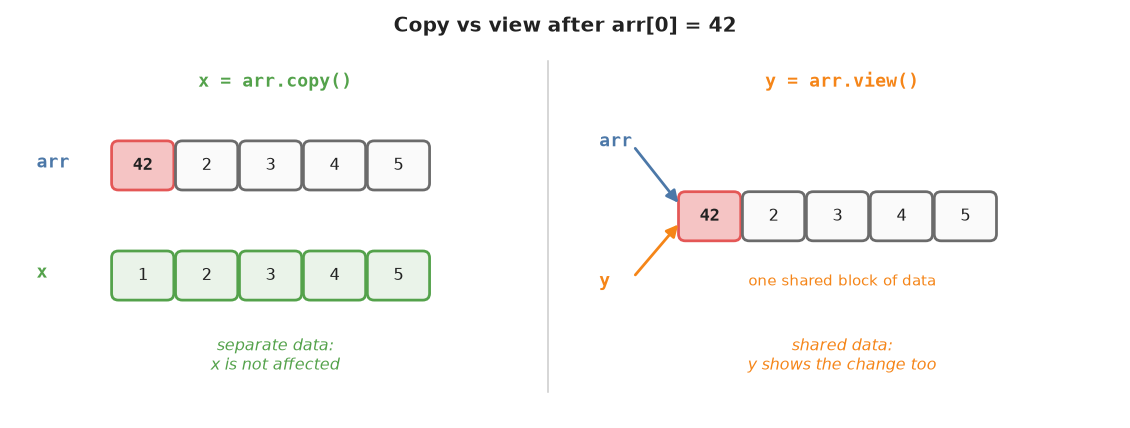

**Make a copy and change the original**

In [1]:
import numpy as np

arr = np.array([1, 2, 3, 4, 5])
x = arr.copy()
arr[0] = 42

print(arr)
print(x)

[42  2  3  4  5]
[1 2 3 4 5]


**Explanation:** copy() creates a new array with its own data. Changing the original array does not affect the copy.

**Make a view and change the original**

In [2]:
import numpy as np

arr = np.array([1, 2, 3, 4, 5])
x = arr.view()
arr[0] = 42

print(arr)
print(x)

[42  2  3  4  5]
[42  2  3  4  5]


**Explanation:** view() creates a new array object that looks at the same data. Changing the original array also changes the view.

**Make a view and change the view**

In [3]:
import numpy as np

arr = np.array([1, 2, 3, 4, 5])
x = arr.view()
x[0] = 31

print(arr)
print(x)

[31  2  3  4  5]
[31  2  3  4  5]


**Explanation:** The link works both ways: changing the view also changes the original array, because they share one block of data.

**Diagram:** base is None for an array that owns its data, and points to the original for a view.

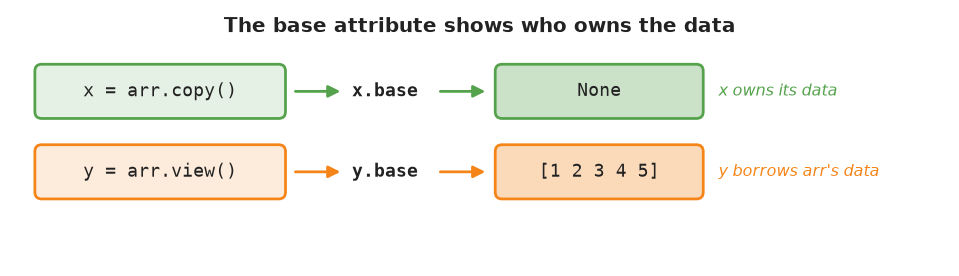

**Check whether an array owns its data**

In [4]:
import numpy as np

arr = np.array([1, 2, 3, 4, 5])

x = arr.copy()
y = arr.view()

print(x.base)
print(y.base)

None
[1 2 3 4 5]


**Explanation:** Every NumPy array has a base attribute. It is None if the array owns its data. For a view, base refers to the original array.

**Use np.shares_memory()**

In [5]:
import numpy as np

arr = np.array([1, 2, 3, 4, 5])

print(np.shares_memory(arr, arr.copy()))
print(np.shares_memory(arr, arr.view()))

False
True


**Explanation:** np.shares_memory() returns True when two arrays use the same data. It is another way to tell a view from a copy.

**Slices are views**

In [6]:
import numpy as np

arr = np.array([1, 2, 3, 4, 5])

part = arr[1:4]
part[:] = 0

print(part)
print(arr)
print(part.base is arr)

[0 0 0]
[1 0 0 0 5]
True


**Explanation:** A basic slice is a view, so setting all of its elements to 0 changes the original array as well.

**Plain assignment is not a copy**

In [7]:
import numpy as np

arr = np.array([1, 2, 3, 4, 5])

same = arr
same[0] = 100

print(arr)
print(same is arr)

[100   2   3   4   5]
True


**Explanation:** Writing same = arr does not create a new array at all; both names refer to the same object. Use copy() when an independent array is needed.

**Make an independent copy of a slice**

In [8]:
import numpy as np

arr = np.array([1, 2, 3, 4, 5])

part = arr[1:4].copy()
part[:] = 0

print(part)
print(arr)

[0 0 0]
[1 2 3 4 5]


**Explanation:** Calling copy() on a slice gives an independent array, so changing it leaves the original unchanged.

## Observation

- copy() creates a new array with its own data; changes to either array do not affect the other.
- view() creates a new array that shares the original data; changes to either one show in both.
- The base attribute is None for an array that owns its data and refers to the original for a view.
- np.shares_memory() checks whether two arrays use the same data.
- Basic slices are views, and plain assignment (b = a) does not copy anything.

## Conclusion

Knowing whether an array is a copy or a view prevents accidental changes to data. Views save memory and time, while copy() should be used whenever the original data must stay unchanged.